In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.fft
import scipy.io
import scipy.signal
import seaborn as sns
from matplotlib import pyplot as plt

from config import Config as c

In [2]:
patient_dir = c.CRSIDLAB_DIR / 'patients'

In [3]:
patient_files = sorted(list(patient_dir.iterdir()))
patient_files

[PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p008061_3145453_0020.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p009124_3576649_0016.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p010842_3523295_0005.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p040435_3075521_0044.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p040724_3023009_0005.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p047874_3602666_0050.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p048480_3876369_0016.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p054132_3178762_0004.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p054586_3860079_0019.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p060747_3260530_0003.mat'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/patients/p061642_3102184_0065.mat'),
 PosixPath

In [4]:
patient_ids = [p.name.split('.')[0] for p in patient_files]
patient_ids

['p008061_3145453_0020',
 'p009124_3576649_0016',
 'p010842_3523295_0005',
 'p040435_3075521_0044',
 'p040724_3023009_0005',
 'p047874_3602666_0050',
 'p048480_3876369_0016',
 'p054132_3178762_0004',
 'p054586_3860079_0019',
 'p060747_3260530_0003',
 'p061642_3102184_0065',
 'p063402_3496554_0025',
 'p063646_3089087_0007',
 'p064485_3625999_0008',
 'p064916_3181603_0003',
 'p065728_3034248_0015',
 'p066682_3549618_0015',
 'p067763_3295996_0009',
 'p069006_3098482_0012',
 'p076178_3045819_0010',
 'p076237_3670140_0003',
 'p081037_3281981_0011',
 'p081633_3588494_0011',
 'p082187_3527335_0007',
 'p082245_3407528_0005',
 'p083263_3461856_0017',
 'p083817_3771199_0015',
 'p087470_3376165_0378',
 'p089782_3535449_0001',
 'p090902_3545763_0023',
 'p093566_3385437_0039',
 'p094147_3954762_0029',
 'p096350_3865027_0027',
 'p098484_3465056_0001']

In [5]:
exported_dir = c.CRSIDLAB_DIR / 'grams'

In [6]:
exported_files = sorted(list(exported_dir.iterdir()))
exported_files

[PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_dbp_infofreq_ar.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_dbp_infofreq_fft.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_dbp_infofreq_welch.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_rri_infofreq_ar.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_rri_infofreq_fft.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_rri_infofreq_welch.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_sbp_infofreq_ar.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_sbp_infofreq_fft.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p008061_3145453_0020_sbp_infofreq_welch.txt'),
 PosixPath('crsidlab/CRSIDLab_3_0_Sept2024_Corrigida/grams/p0

In [21]:
pd.read_csv(file, sep='\t', index_col=0, header=0, nrows=3)

,Total,VLF,LF,HF,LF/HF
a.a.,38.3799,25.7744,5.2515,7.3541,0.7141
r.a.,100.0000,67.1560,13.6830,19.1610,0.7141
n.a.,1.0000,NaN,41.6601,58.3399,0.7141


,key,value
0,fs (Hz),4
1,Method,Fourier
2,# of Pts,2048
3,Window,Hanning
4,Welch method samples per segment,----
5,Welch method overlapping samples,----
6,AR order,----


In [7]:
subject_ids = [int(p[2:7]) for p in patient_ids]
subject_ids

[8061,
 9124,
 10842,
 40435,
 40724,
 47874,
 48480,
 54132,
 54586,
 60747,
 61642,
 63402,
 63646,
 64485,
 64916,
 65728,
 66682,
 67763,
 69006,
 76178,
 76237,
 81037,
 81633,
 82187,
 82245,
 83263,
 83817,
 87470,
 89782,
 90902,
 93566,
 94147,
 96350,
 98484]

In [ ]:
# signals = ['rri', 'sbp', 'dbp']
# methods = ['fft', 'welch', 'ar']
# features = []
# for patient_id, subject_id in zip(patient_ids, subject_ids):
#     feats = {}
#     for signal in signals:
#         for method in methods:
#             file = exported_dir / f'{patient_id}_{signal}_infofreq_{method}.txt'
#             df_areas = pd.read_csv(file, sep='\t', index_col=0, header=0, nrows=3)
#             # df_info = pd.read_csv(file, sep='\t', header=None, names=['key', 'value'], skiprows=6, nrows=7)
#             # feats[f'{signal}_{method}_vlf'] = df_areas.loc['r.a.', 'VLF'].item() / 100,
#             feats[f'{signal}_{method}_lf'] = df_areas.loc['r.a.', 'LF'].item() / 100,
#             feats[f'{signal}_{method}_hf'] = df_areas.loc['r.a.', 'HF'].item() / 100,
#             feats[f'{signal}_{method}_r_lf_hf'] = df_areas.loc['r.a.', 'LF/HF'].item(),
#     feats = {'subject_id': subject_id} | {k: v[0] for k, v in feats.items()}
#     features.append(feats)
# # df_features = pd.DataFrame(index=subject_ids, data=features)
# df_features = pd.DataFrame(data=features)
# df_features

In [ ]:
# df_features.to_csv(c.CSV_DIR / 'features_ecg+abp.csv', index=False)

In [ ]:
signals = ['rri', 'sbp', 'dbp']
methods = ['fft', 'welch', 'ar']
features = []
for patient_id, subject_id in zip(patient_ids, subject_ids):
    feats = {}
    for signal in signals:
        for method in methods:
            file = exported_dir / f'{patient_id}_{signal}_infofreq_{method}.txt'
            df_areas = pd.read_csv(file, sep='\t', index_col=0, header=0, nrows=3)
            # df_info = pd.read_csv(file, sep='\t', header=None, names=['key', 'value'], skiprows=6, nrows=7)
            # feats[f'{signal}_{method}_vlf'] = df_areas.loc['r.a.', 'VLF'].item() / 100,
            feats[f'{signal}_{method}_lf'] = df_areas.loc['r.a.', 'LF'].item() / 100,
            feats[f'{signal}_{method}_hf'] = df_areas.loc['r.a.', 'HF'].item() / 100,
            feats[f'{signal}_{method}_r_lf_hf'] = df_areas.loc['r.a.', 'LF/HF'].item(),
    feats = {'subject_id': subject_id} | {k: v[0] for k, v in feats.items()}
    features.append(feats)
# df_features = pd.DataFrame(index=subject_ids, data=features)
df_features = pd.DataFrame(data=features)
df_features

In [93]:
df_features.to_csv(c.CSV_DIR / 'features_ecg+abp.csv', index=False)

In [69]:
import ppg_funcs
from config import Config as c

In [71]:
df_subjects = ppg_funcs.load_subjects()
# df_subjects

In [77]:
df = df_subjects[['subject_id', 'class']].merge(df_features, on='subject_id').set_index('subject_id')
df

,class,rri_fft_vlf,rri_fft_lf,rri_fft_hf,rri_fft_r_lf_hf,rri_welch_vlf,rri_welch_lf,rri_welch_hf,rri_welch_r_lf_hf,rri_ar_vlf,...,dbp_fft_hf,dbp_fft_r_lf_hf,dbp_welch_vlf,dbp_welch_lf,dbp_welch_hf,dbp_welch_r_lf_hf,dbp_ar_vlf,dbp_ar_lf,dbp_ar_hf,dbp_ar_r_lf_hf
subject_id,,,,,,,,,,,,,,,,,,,,,
48480,control,0.80334,0.05011,0.14655,0.3419,0.69116,0.15080,0.15804,0.9542,0.70745,...,0.35846,0.6249,0.33381,0.27433,0.39187,0.7001,0.36306,0.25750,0.37944,0.6786
63646,control,0.58807,0.39731,0.01462,27.1741,0.65647,0.32041,0.02311,13.8630,0.70883,...,0.33945,0.7665,0.36147,0.18916,0.44937,0.4210,0.39553,0.14611,0.45836,0.3188
64485,control,0.35159,0.47015,0.17826,2.6375,0.43542,0.39151,0.17307,2.2622,0.39102,...,0.15338,4.3438,0.19451,0.60820,0.19729,3.0827,0.15670,0.64160,0.20170,3.1809
64916,control,0.51843,0.14541,0.33616,0.4325,0.59931,0.11814,0.28255,0.4181,0.47374,...,0.10769,3.2293,0.56959,0.32404,0.10637,3.0463,0.58246,0.31655,0.10099,3.1344
66682,control,0.31991,0.19194,0.48815,0.3932,0.31692,0.25704,0.42604,0.6033,0.30324,...,0.45315,0.2152,0.35144,0.13840,0.51016,0.2713,0.34761,0.16316,0.48923,0.3335
67763,control,0.67651,0.11073,0.21276,0.5204,0.56094,0.18715,0.25191,0.7429,0.64565,...,0.27056,1.7008,0.34004,0.39516,0.26480,1.4923,0.48885,0.25165,0.25950,0.9697
69006,control,0.42018,0.29949,0.28033,1.0683,0.39703,0.37328,0.22969,1.6252,0.45190,...,0.37109,0.6276,0.31596,0.25865,0.42539,0.6080,0.37506,0.19801,0.42693,0.4638
76178,control,0.56755,0.32726,0.10519,3.1110,0.56223,0.38955,0.04822,8.0778,0.51748,...,0.06647,5.9845,0.50340,0.44192,0.05468,8.0819,0.59556,0.35492,0.04952,7.1679
76237,control,0.72231,0.14142,0.13627,1.0379,0.64118,0.16268,0.19614,0.8294,0.65688,...,0.02976,15.9247,0.47291,0.50096,0.02613,19.1707,0.50910,0.47397,0.01693,27.9961


/tmp/ipykernel_155951/1337994274.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  corr = df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()


<Axes: >

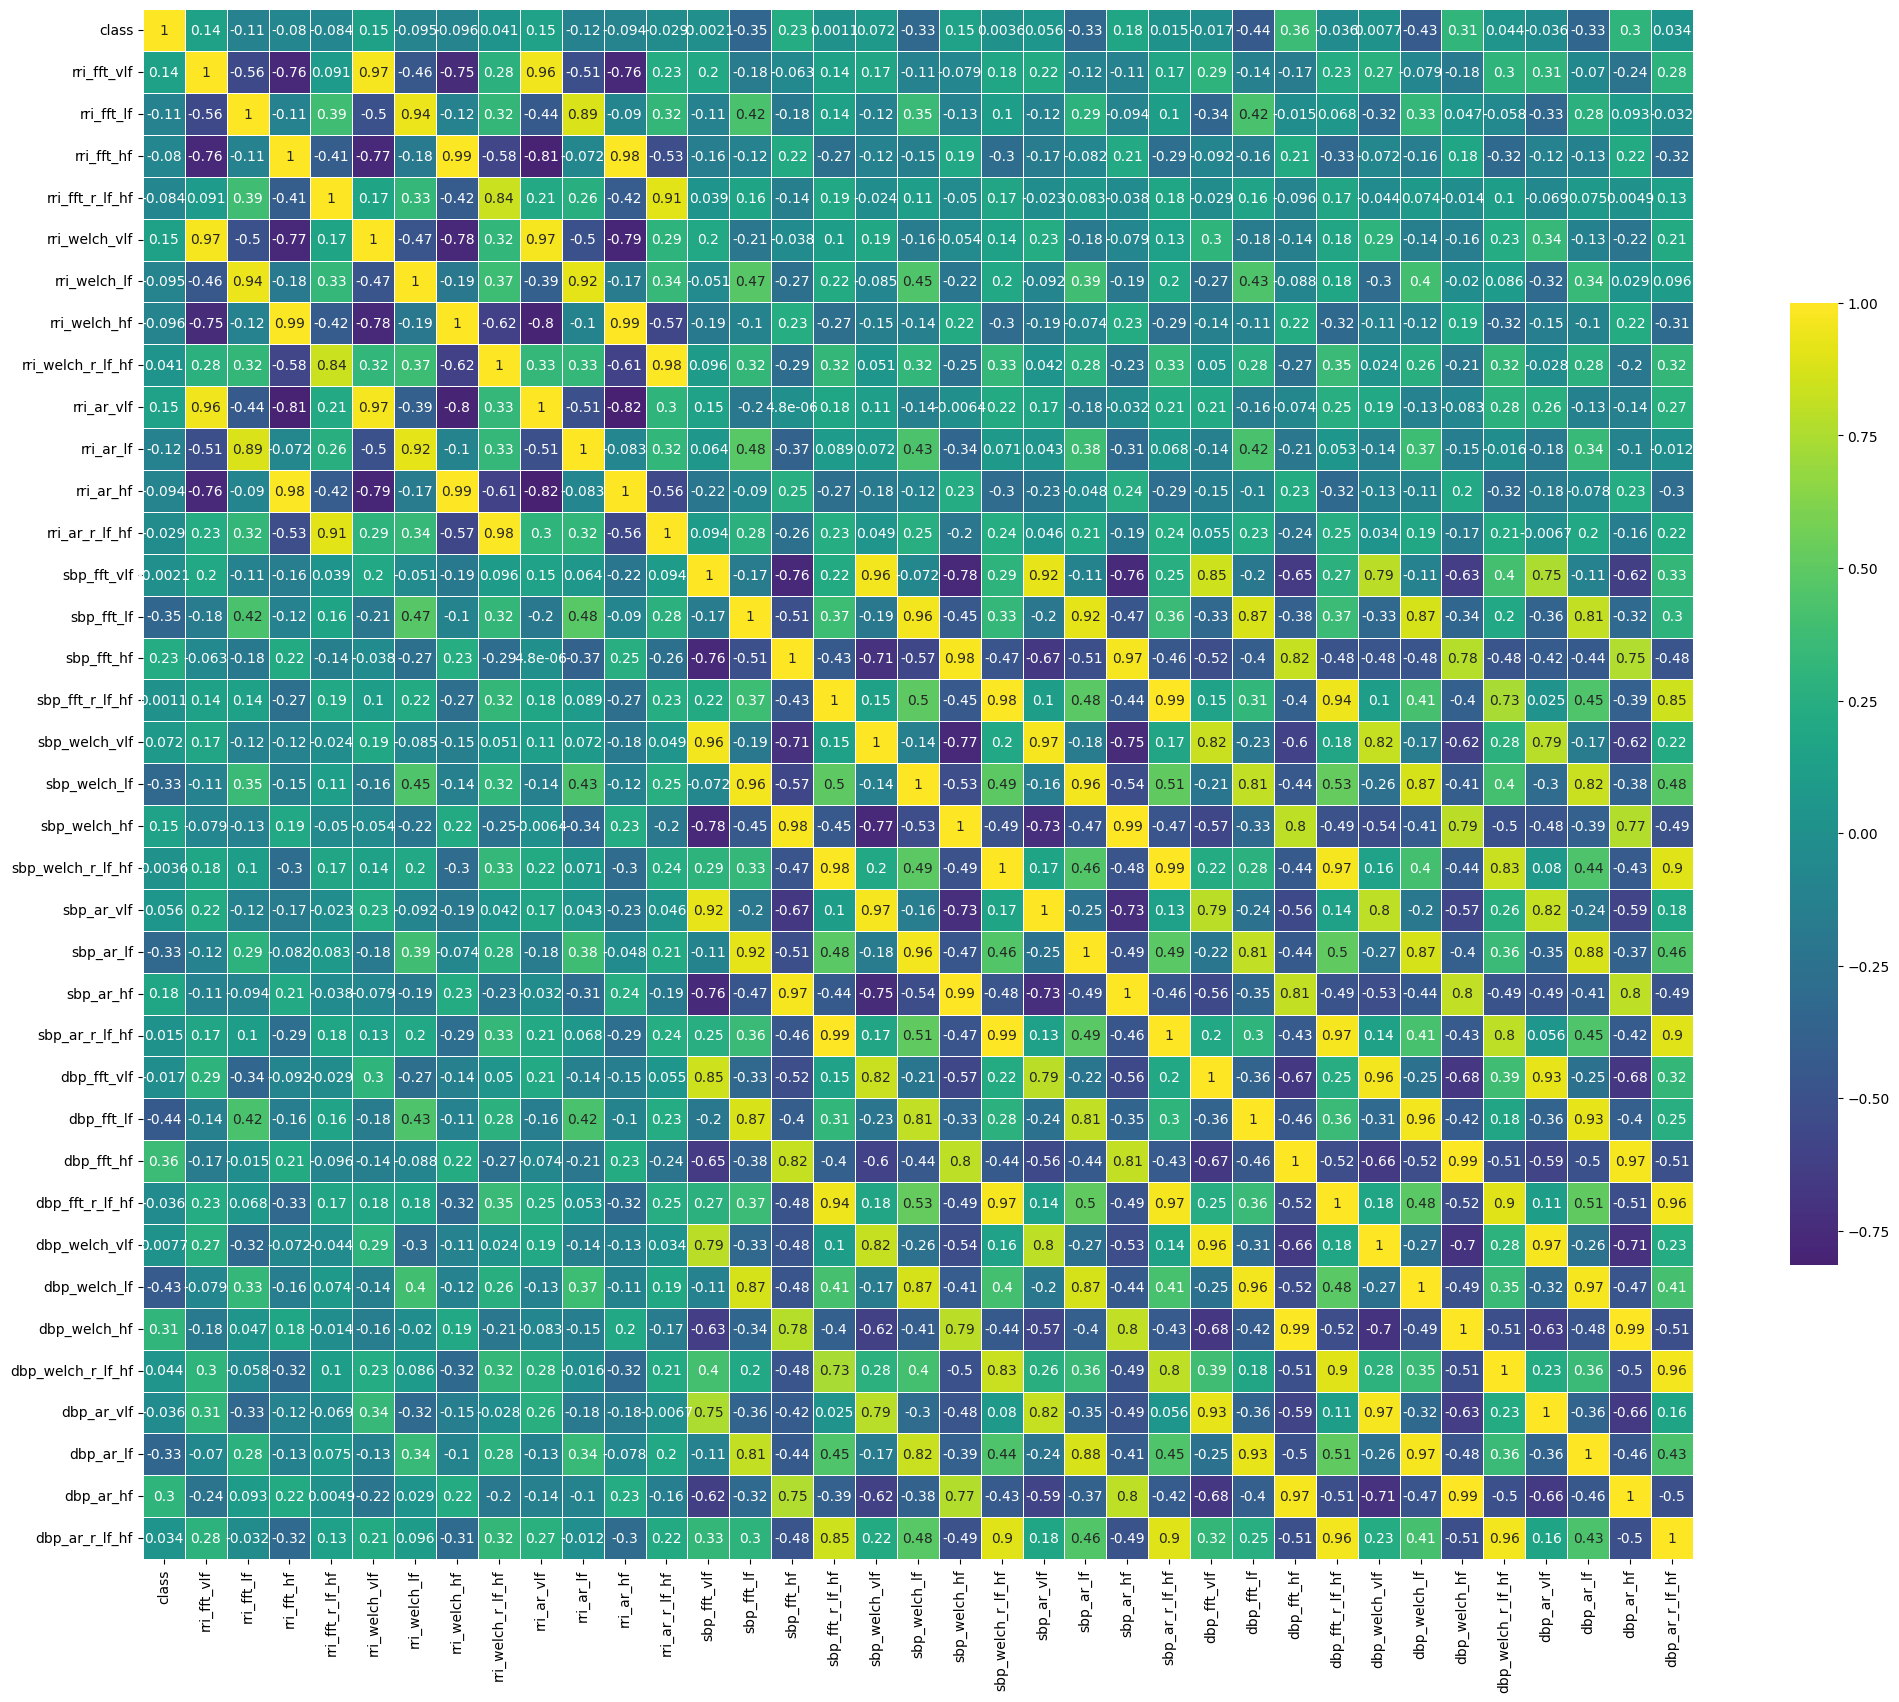

In [82]:
corr = df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()
fig, ax = plt.subplots(figsize=(25, 25))
cmap = 'viridis'
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, mask=mask, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})
sns.heatmap(corr, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [89]:
keep_cols = ['class'] + [c for c in df.columns if 'fft' in c and ('rri' in c or 'dbp' in c)]
df[keep_cols]

,class,rri_fft_vlf,rri_fft_lf,rri_fft_hf,rri_fft_r_lf_hf,dbp_fft_vlf,dbp_fft_lf,dbp_fft_hf,dbp_fft_r_lf_hf
subject_id,,,,,,,,,
48480,control,0.80334,0.05011,0.14655,0.3419,0.41753,0.22401,0.35846,0.6249
63646,control,0.58807,0.39731,0.01462,27.1741,0.40036,0.26019,0.33945,0.7665
64485,control,0.35159,0.47015,0.17826,2.6375,0.18039,0.66623,0.15338,4.3438
64916,control,0.51843,0.14541,0.33616,0.4325,0.54455,0.34776,0.10769,3.2293
66682,control,0.31991,0.19194,0.48815,0.3932,0.44931,0.09754,0.45315,0.2152
67763,control,0.67651,0.11073,0.21276,0.5204,0.26928,0.46016,0.27056,1.7008
69006,control,0.42018,0.29949,0.28033,1.0683,0.39601,0.23289,0.37109,0.6276
76178,control,0.56755,0.32726,0.10519,3.1110,0.53574,0.39779,0.06647,5.9845
76237,control,0.72231,0.14142,0.13627,1.0379,0.49631,0.47393,0.02976,15.9247


/tmp/ipykernel_155951/2846512454.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  corr = df[keep_cols].replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()


<Axes: >

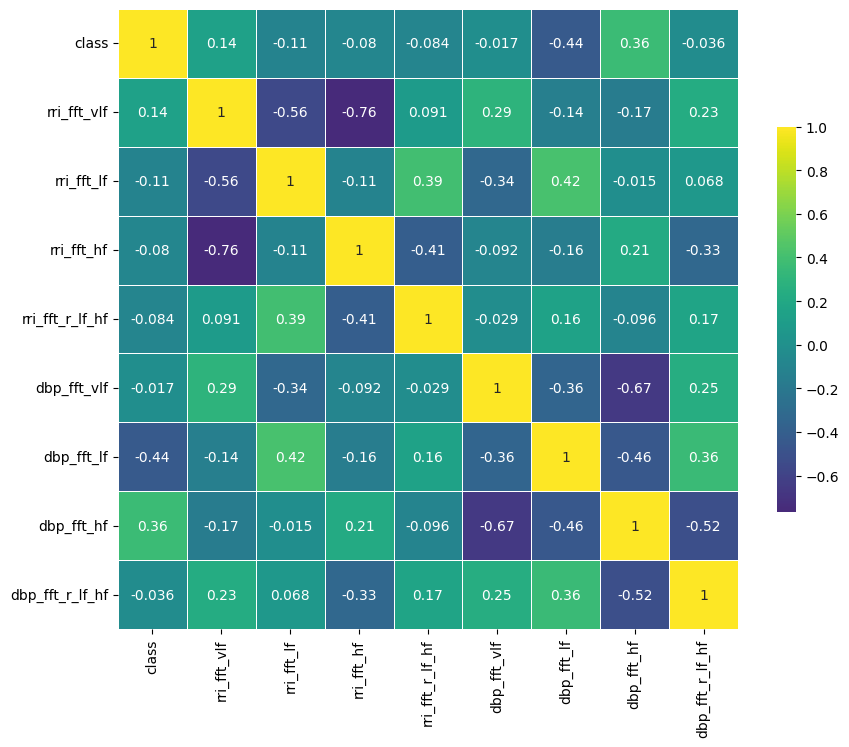

In [92]:
corr = df[keep_cols].replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()
fig, ax = plt.subplots(figsize=(10, 10))
cmap = 'viridis'
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, mask=mask, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})
sns.heatmap(corr, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})